# House Price Prediction 🏠
**Problem:** Predict the median house value of a California district from its location, rooms, population and median income.
**Type:** Regression · **Dataset:** 20,640 districts (California Housing)

## 1. Load the data

In [1]:
import pandas as pd
import numpy as np

URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv(URL)
print(df.shape)
df.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 2. Feature engineering
Raw totals (rooms, bedrooms) are less useful than **per-household averages**, so I create them. Missing bedroom values are filled with the median, and `ocean_proximity` is one-hot encoded.

In [2]:
data = df.copy()
data["total_bedrooms"] = data["total_bedrooms"].fillna(data["total_bedrooms"].median())
data["rooms_per_household"] = data["total_rooms"] / data["households"]
data["bedrooms_per_room"] = data["total_bedrooms"] / data["total_rooms"]
data["population_per_household"] = data["population"] / data["households"]

feature_cols = ["longitude", "latitude", "housing_median_age", "total_rooms",
                "total_bedrooms", "population", "households", "median_income",
                "rooms_per_household", "bedrooms_per_room", "population_per_household",
                "ocean_proximity"]
X = pd.get_dummies(data[feature_cols], columns=["ocean_proximity"], drop_first=True)
y = data["median_house_value"]
print(X.shape)

(20640, 15)


## 3. Train a linear model and a Random Forest, then compare

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

def report(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(f"{name:18s} MAE: ${mean_absolute_error(y_test, pred):,.0f}   "
          f"RMSE: ${root_mean_squared_error(y_test, pred):,.0f}   "
          f"R2: {r2_score(y_test, pred):.3f}")
    return model, pred

lin_model, _ = report("Linear Regression", LinearRegression())
rf_model, rf_pred = report("Random Forest", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))

Linear Regression  MAE: $50,889   RMSE: $72,669   R2: 0.597


Random Forest      MAE: $32,181   RMSE: $50,075   R2: 0.809


## 4. Predicted vs actual prices (Random Forest)

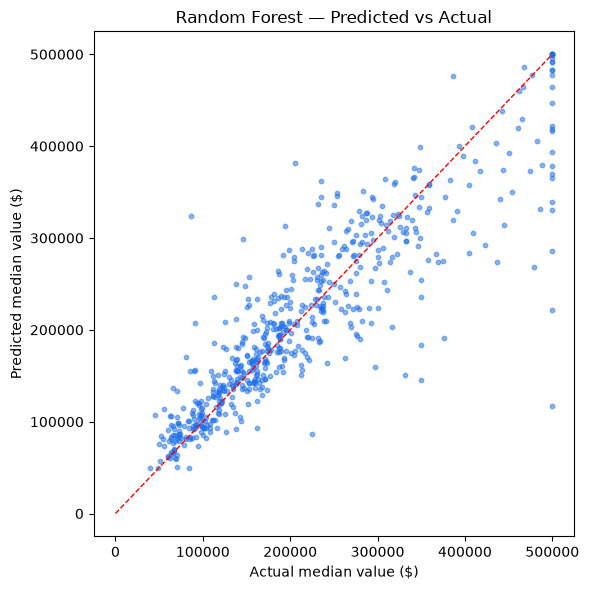

In [4]:
import matplotlib.pyplot as plt

sample = np.random.RandomState(0).choice(len(y_test), 600, replace=False)
plt.figure(figsize=(6, 6))
plt.scatter(y_test.iloc[sample], rf_pred[sample], s=10, alpha=0.5, color="#1F6FEB")
lims = [0, 500000]
plt.plot(lims, lims, "r--", linewidth=1)
plt.xlabel("Actual median value ($)")
plt.ylabel("Predicted median value ($)")
plt.title("Random Forest — Predicted vs Actual")
plt.tight_layout()
plt.savefig("predicted_vs_actual.png", dpi=150)
plt.show()

## What I learned
- **Median income is the strongest single signal** for house prices — location (longitude/latitude) comes next.
- A Random Forest clearly beats Linear Regression because prices react non-linearly to income and location.
- Engineered features (rooms per household etc.) help both models — good features beat fancier algorithms.